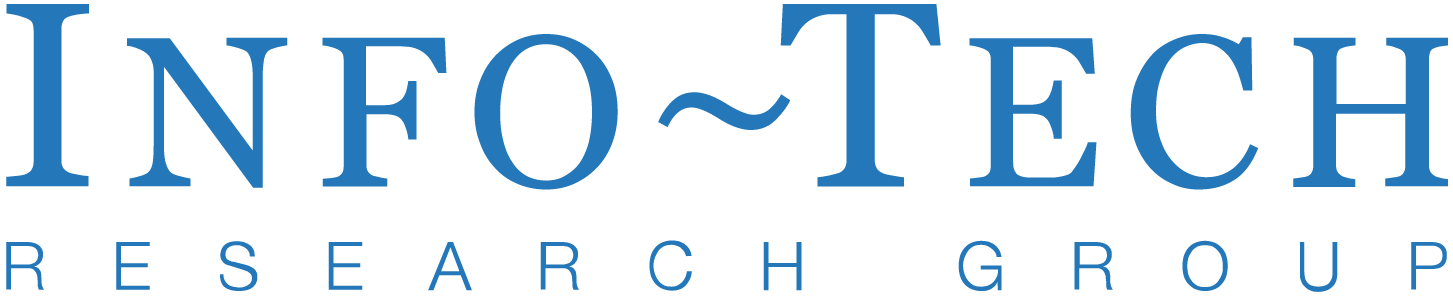

# **Licensing and Proprietary Information Notice**

This notebook is for **Educational purposes** only.

By using this notebook, users agree to respect the intellectual property rights of InfoTech Research Group and to use the provided content and technology in accordance with all applicable laws and regulations.

By uploading any data to the notebook User agrees that uploads will not:

- Include misrepresentative, obscene, libelous, defamatory, threatening, harassing, abusive, hateful, sexually explicit, sexually oriented, profane or embarrassing material, as determined by Info-Tech in its sole discretion;

- Be otherwise objectionable.

### **Limitation of Liability**

> InfoTech disclaims all liability for any actions taken by users outside the educational scope of this course involving the use of this Google Colab notebook. Info-Tech is not liable for any technical issues resulting from use of the Google Colab notebook and User must resolve any technical issues with Google Colab. Should you choose to download this notebook and apply its contents for personal or other uses, you accept full responsibility for any outcomes that arise. InfoTech is not responsible for any direct, indirect, incidental, or consequential damages that may result from such use.


### Citation

Credits to: Darts (Python library)

@article{JMLR:v23:21-1177,
  author  = {Julien Herzen and Francesco LÃ¤ssig and Samuele Giuliano Piazzetta and Thomas Neuer and LÃ©o Tafti and Guillaume Raille and Tomas Van Pottelbergh and Marek Pasieka and Andrzej Skrodzki and Nicolas Huguenin and Maxime Dumonal and Jan KoÅ›cisz and Dennis Bader and FrÃ©dÃ©rick Gusset and Mounir Benheddi and Camila Williamson and Michal Kosinski and Matej Petrik and GaÃ«l Grosch},
  title   = {Darts: User-Friendly Modern Machine Learning for Time Series},
  journal = {Journal of Machine Learning Research},
  year    = {2022},
  volume  = {23},
  number  = {124},
  pages   = {1-6},
  url     = {http://jmlr.org/papers/v23/21-1177.html}
}



---



---



# How to use this Notebook

If you do not see any sort of GPU:

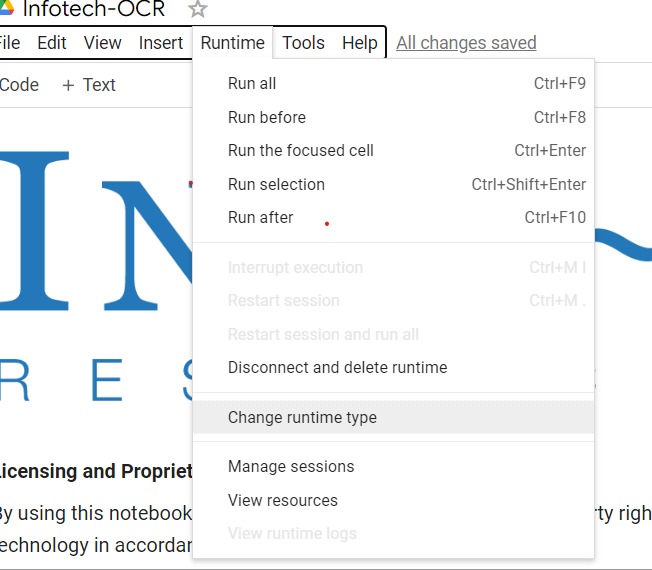

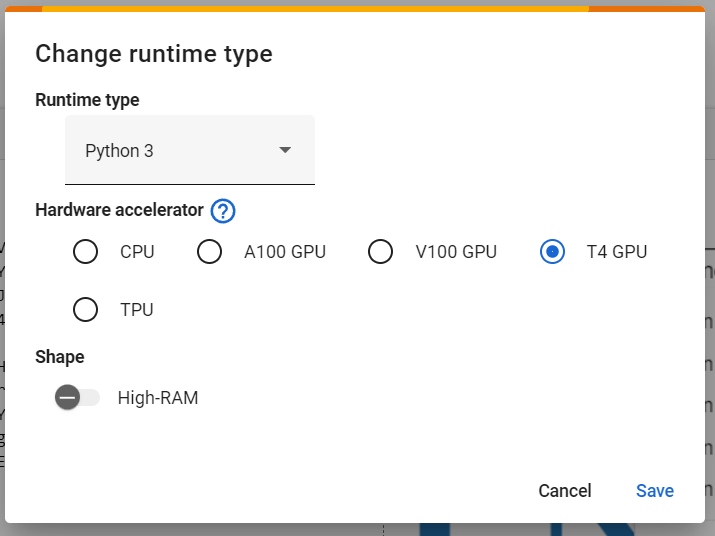

Click the "Connect" button.
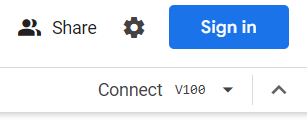


Then Hit the "Play" Button on each cell.

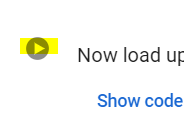

# Software Setup 🔧

In [ ]:
%%capture
#@title Installing required libraries!
#@markdown This section will install necessary libraries and setup the environment.

#@markdown Press ▶
# Installation commands
!pip install darts

In [ ]:
#@title Importing required libraries!
#@markdown Let's now load in the library along with it's in built datasets.

#@markdown Press ▶
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from darts import TimeSeries
from darts.datasets import AirPassengersDataset, AusBeerDataset, HeartRateDataset,MonthlyMilkDataset

import ipywidgets as widgets
from IPython.display import display, Markdown

from PIL import Image

lmscode = "deHn6E6ARRK5zeuj"
key = {
    "1": "3",
    "2": "2",
    "3": "3",
    "4": "3",
}

user_answers = {}

# Function to check answers and calculate score
def grade(user_answers, key):
    correct_answers_count = 0
    unanswered_questions = []
    final_score = 0
    is_perfect = False  # Initialize the perfection flag as False

    for question, correct_answer in key.items():
        user_answer = user_answers.get(question)
        if user_answer is None:
            unanswered_questions.append(question)  # Collecting unanswered questions
            continue  # Skip further processing for this iteration

        if user_answer == correct_answer:
            print(f"Question {question}: Correct!")
            correct_answers_count += 1
        else:
            #print(f"Question {question}: Incorrect! The answer is {correct_answer}")
            print(f"Question {question}: Incorrect!")

    total_questions = len(key)
    if unanswered_questions:
        print("You have not answered all the questions. Please complete the following questions before getting your final grade:")
        print(", ".join(unanswered_questions))
    else:
        # Calculate and print final score if all questions are answered
        final_score = correct_answers_count / total_questions * 100  # Final score as a percentage
        is_perfect = correct_answers_count == total_questions  # Set perfection flag based on score
        print("--------------------------------------------------------------------------")
        print(f"Final Score: {final_score}% ({correct_answers_count} out of {total_questions} correct)")
        print("--------------------------------------------------------------------------")

    return final_score, is_perfect


# Foundational Knowledge 📚

Time series forecasting is a powerful statistical technique used to make predictions about future events based on patterns observed in past data. At its core, time series forecasting analyzes time-ordered data points—collected over regular time intervals—to model and predict future values. This method is crucial for any domain where understanding and anticipating the future based on past trends can inform decision-making and strategic planning.

**What is Time Series Forecasting?**

In technical terms, time series forecasting involves using models to predict future observations of a variable of interest, such as sales figures, stock prices, weather conditions, or energy consumption, based on historical time series data. These predictions are essential for planning and are used to answer questions like "How much of a product will we sell in the next quarter?" or "What will be the temperature tomorrow at noon?"

**Applications and Use Cases**

The applicability of time series forecasting spans various sectors and industries, demonstrating its versatility and importance. Here are a few notable examples:

- **Finance and Economics:** Forecasting stock prices, economic indicators, demand for banking services, and currency exchange rates to make informed investment decisions and policy formulations.
- **Retail and Supply Chain Management**: Predicting future product demand to optimize inventory levels, reduce costs, and increase customer satisfaction by ensuring product availability.
- **Energy Sector:** Estimating future energy demand and renewable energy output to ensure grid stability and optimize energy distribution.
- **Healthcare:** Anticipating the spread of diseases, patient admissions, and required resources to improve healthcare services and patient care.
- **Weather Forecasting and Environmental Monitoring:** Predicting weather conditions, natural disaster events, and environmental changes to mitigate risks and protect communities.


**Why Time Series Forecasting?**

The importance of time series forecasting lies in its ability to provide actionable insights and foresight in an uncertain future. By understanding potential future scenarios, organizations can strategize more effectively, allocate resources more efficiently, and gain a competitive edge. The predictive power of time series forecasting enables proactive rather than reactive decision-making, turning historical data into a valuable asset for future planning.

# Application 🍳

In this notebook, we will be using [**Darts**](https://unit8co.github.io/darts/), a Python library for user-friendly forecasting and anomaly detection on time series. The library also makes it easy to backtest models, combine the predictions of several models, and take external data into account. Darts supports both univariate and multivariate time series and models. The ML-based models can be trained on potentially large datasets containing multiple time series, and some of the models offer a rich support for probabilistic forecasting. Darts also offers extensive anomaly detection capabilities.

**Understanding Time Series Dataframes**

When working with time series forecasting, it's essential to structure your data correctly to facilitate analysis and model training. A time series dataframe is a tabular representation of your data, where each row corresponds to a specific time point, and columns represent different variables you're tracking over time.

**Basic Structure of a Time Series Dataframe**

A typical time series dataframe consists of at least two columns:
- **Date (X)**: This column contains the timestamps for each observation. Dates should be in a consistent format (e.g., YYYY-MM-DD) and are usually set as the dataframe's index. This arrangement allows for easy manipulation and analysis of time series data.
- **Variable (Y)**: This column represents the data we're interested in forecasting. It could be anything from sales numbers, stock prices, weather measurements, or any other quantity that changes over time.

**Example**

Here is a simple example of what a time series dataframe might look like if you're tracking monthly sales data:

| Date       | Sales   |
|------------|---------|
| 2020-01-01 | 200     |
| 2020-02-01 | 180     |
| 2020-03-01 | 210     |
| ...        | ...     |
| 2021-12-01 | 250     |

**Preparing Your Data**

If you plan to work on your time series forecasting project, you'll need to prepare your data in a similar format. Here are a few tips to get started:
- **Collect Your Data**: Gather your observations and make sure your dates are accurate and in the correct format.
- **Choose Your Variable**: Decide on the variable(s) you want to forecast. If tracking more than one variable, each should have its own column in the dataframe.
- **Organize Your Dataframe**: Arrange your data so that each row corresponds to a time point, with the date as the index and your variable(s) as column(s).

By structuring your data in this manner, you'll be setting a strong foundation for your time series analysis and making the most out of the forecasting tools and techniques we'll explore in this notebook.


In [ ]:
#@title Read data and build a timeseries
#@markdown >⭐ As a reminder, press play when you are executing all the cells ▶

#@markdown Now that we know how the datasets work, let's take a look at the dataset we will be working with today.
#@markdown Take a look at how our data is structured. (Make note of this if you want to bring in your own data!)

dataset = AirPassengersDataset()
series = dataset.load()
df = series.to_dataframe()

print("Monthly Air Passengers Dataset, from 1949 to 1960.")
display(df.head(10))

#@markdown Press ▶

Monthly Air Passengers Dataset, from 1949 to 1960.


component,#Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0
1949-06-01,135.0
1949-07-01,148.0
1949-08-01,148.0
1949-09-01,136.0


<Axes: xlabel='Month'>

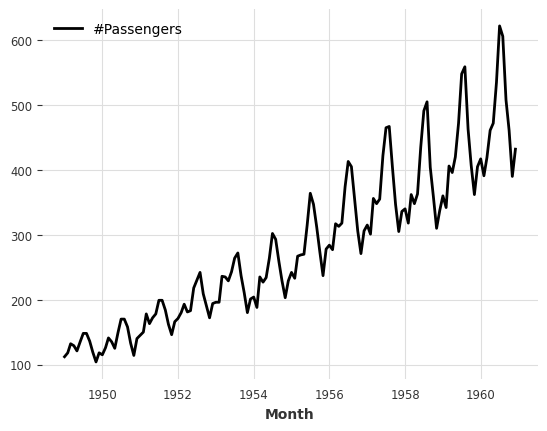

In [ ]:
#@markdown Let's also plot this just so we know what we are looking at!

#@markdown Press ▶
series.plot()

<Axes: xlabel='Month'>

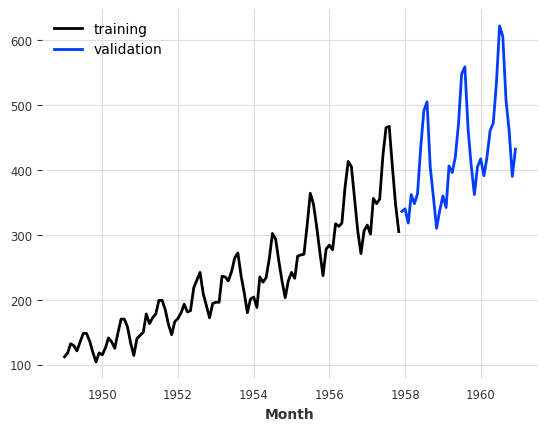

In [ ]:
#@title Creating a training and validation series
#@markdown We use the training series to teach the model and then test it with the validation series.

#@markdown Press ▶
train, val = series.split_before(0.75)
train.plot(label="training")
val.plot(label="validation")

<Axes: xlabel='Month'>

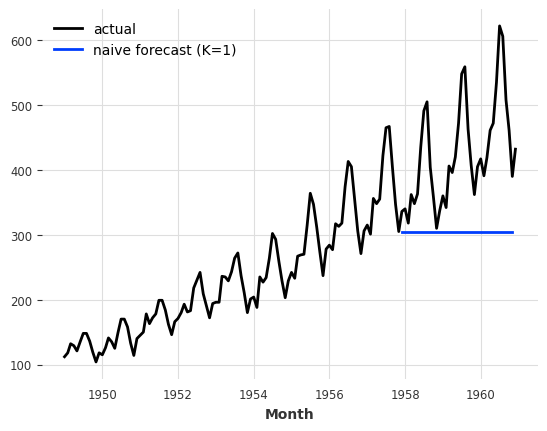

In [ ]:
#@title Training forecasting models and making predictions
#@markdown Darts has some simple starting point models we call 'naive.' These help us understand the minimum accuracy we might expect from more complex models. For instance, one of these simple models just keeps using a past value from a specific number of steps back. The most straightforward version uses the very last value we saw and keeps predicting that same value for the future.

#@markdown Press ▶
from darts.models import NaiveSeasonal

naive_model = NaiveSeasonal(K=1)
naive_model.fit(train)
naive_forecast = naive_model.predict(36)

series.plot(label="actual")
naive_forecast.plot(label="naive forecast (K=1)")

There is seasonality of order 12.


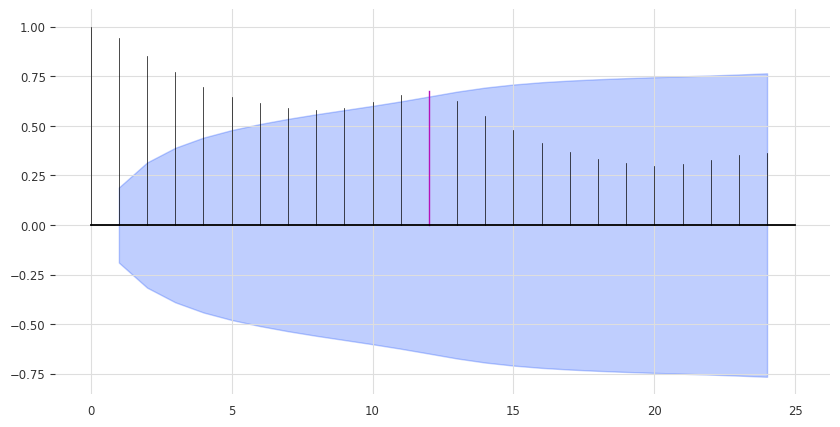

In [ ]:
#@title Inspect Seasonality
#@markdown Our initial simple model might be too simplistic. We can make better predictions by noticing and using patterns that repeat over time, like how sales might go up around the same time every year. We check this by looking at a specific graph (auto-correlation function), which shows us that there's indeed a yearly pattern. We see a clear marker at the 12-month point, indicating this yearly repetition.

#@markdown More on Seasonality:

#@markdown The stronger correlation, the more similar the signal is when we compare it to itself at a given time interval. A spike at 12 months indicates that every 12 months the signal appears to cycle


#@markdown Press ▶
from darts.utils.statistics import plot_acf, check_seasonality

plot_acf(train, m=12, alpha=0.05)
for m in range(2, 25):
    is_seasonal, period = check_seasonality(train, m=m, alpha=0.05)
    if is_seasonal:
        print("There is seasonality of order {}.".format(period))

<Axes: xlabel='Month'>

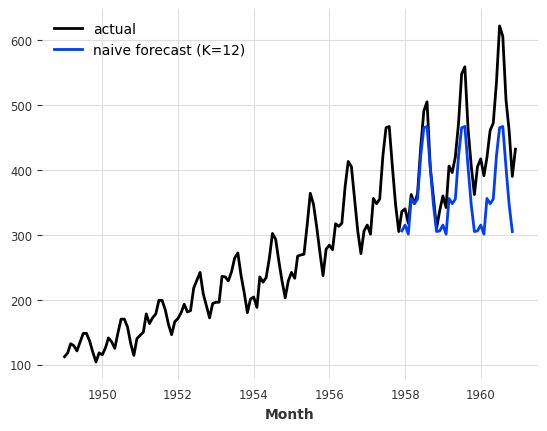

In [ ]:
#@markdown Let’s try the NaiveSeasonal model again with a seasonality of 12:

#@markdown Note: NaiveSeasonal model is built to handle cyclical signals.

#@markdown Press ▶
seasonal_model = NaiveSeasonal(K=12)
seasonal_model.fit(train)
seasonal_forecast = seasonal_model.predict(36)

series.plot(label="actual")
seasonal_forecast.plot(label="naive forecast (K=12)")

Mean absolute percentage error for the combined naive drift + seasonal: 6.47%.


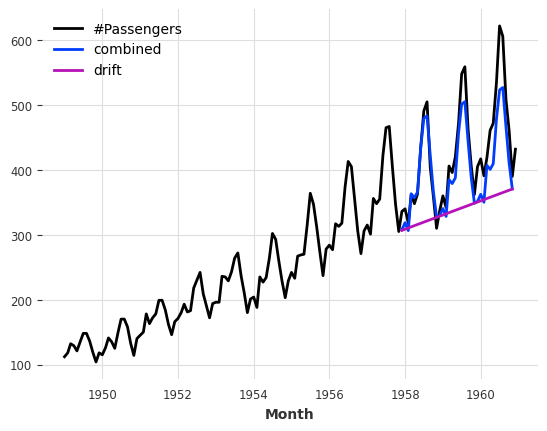

In [ ]:
#@markdown To further refine our predictions, we introduce another simple model, the NaiveDrift, that takes into account the overall direction or trend of our data. It looks at where we started and where we ended, and draws a straight line between these points to predict future values. This approach gives us a more realistic forecast, even though it's still pretty basic and not completely accurate.

from darts.models import NaiveDrift

drift_model = NaiveDrift()
drift_model.fit(train)
drift_forecast = drift_model.predict(36)

combined_forecast = drift_forecast + seasonal_forecast - train.last_value()

series.plot()
combined_forecast.plot(label="combined")
drift_forecast.plot(label="drift")

from darts.metrics import mape

print(
    "Mean absolute percentage error for the combined naive drift + seasonal: {:.2f}%.".format(
        mape(series, combined_forecast)
    )
)

In [ ]:
#@title Computing error metrics
#@markdown Even with our improved forecast, we aim to do better with more advanced models. Before moving on, we establish a benchmark for improvement using a common error metric called the Mean Absolute Percentage Error (MAPE). Although MAPE has its drawbacks and might not always be the best choice, it's useful for us because it's easy to understand and applies regardless of the scale of our data.

#@markdown Press ▶

from darts.metrics import mape

print(
    "Mean absolute percentage error for the combined naive drift + seasonal: {:.2f}%.".format(
        mape(series, combined_forecast)
    )
)

Mean absolute percentage error for the combined naive drift + seasonal: 6.47%.


In [ ]:
#@title Quickly try out several models

#@markdown Let’s train a few more models and compute their respective MAPE on the validation set. We only built these models with their default parameters. Fine-tuning these models could yield even better results. For advanced techniques, please reach out to Info-tech.

#@markdown Press ▶
from darts.models import ExponentialSmoothing, TBATS, AutoARIMA, Theta

def eval_model(model):
    print(f"Training model {model.__class__.__name__}...")
    model.fit(train)
    forecast = model.predict(len(val))
    print("model {} obtains MAPE: {:.2f}%".format(model.__class__.__name__, mape(val, forecast)))
    print("---------------")

#@markdown - **Exponential Smoothing**: Useful for data with trends and seasonal patterns, adjusts prediction based on recent data points. However, it can overfit if the data contains a lot of noise or irregularities.
eval_model(ExponentialSmoothing())

#@markdown - **TBATS**: Suitable for complex seasonal patterns and multiple seasonalities, ideal for daily or sub-daily data. It can be computationally intensive, especially with large datasets.
eval_model(TBATS(season_length=1))

#@markdown - **AutoARIMA**: Automatically selects the best ARIMA model parameters, great for non-seasonal time series data with trends. The model selection process can be slow, and it may not handle seasonal data well without additional adjustments.
eval_model(AutoARIMA())

#@markdown - **Theta**: Simplified approach to forecasting, effective for smooth time series, and often provides robust forecasts. However, it might underperform on data with sharp fluctuations or high variability.
eval_model(Theta())


Training model ExponentialSmoothing...
model ExponentialSmoothing obtains MAPE: 7.86%
---------------
Training model TBATS...
model TBATS obtains MAPE: 34.22%
---------------
Training model AutoARIMA...
model AutoARIMA obtains MAPE: 11.42%
---------------
Training model Theta...
model Theta obtains MAPE: 7.52%
---------------


The MAPE is: 5.13, with the best theta = -8.0.


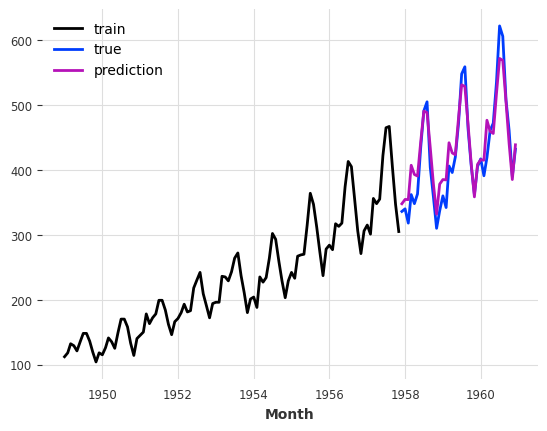

In [ ]:
#@title Searching for hyper-parameters with the Theta method

#@markdown The Theta model, included in Darts, is based on a method developed by Assimakopoulos and Nikolopoulos. It's been particularly effective in forecasting competitions. This method simplifies the forecast by assuming the data can be split into two parts—one that changes over time and one that doesn’t—and then adjusts the forecast accordingly.

#@markdown We chose the Theta method because of its simplicity and proven track record in various forecasting competitions. Its unique approach to decomposing the time series into two distinct components allows it to effectively capture underlying trends, making it suitable for our data set.

#@markdown The hyper-parameter we are tuning here is the 'theta' parameter, which controls the level of dampening applied to the trend component. By experimenting with different theta values, we aim to optimize the model's accuracy, measured by the Mean Absolute Percentage Error (MAPE).

#@markdown Press ▶
thetas = 2 - np.linspace(-10, 10, 50)

best_mape = float("inf")
best_theta = 0

for theta in thetas:
    model = Theta(theta)
    model.fit(train)
    pred_theta = model.predict(len(val))
    res = mape(val, pred_theta)

    if res < best_mape:
        best_mape = res
        best_theta = theta

best_theta_model = Theta(best_theta)
best_theta_model.fit(train)
pred_best_theta = best_theta_model.predict(len(val))

train.plot(label="train")
val.plot(label="true")
pred_best_theta.plot(label="prediction")

print(
    "The MAPE is: {:.2f}, with the best theta = {}.".format(
        mape(val, pred_best_theta), best_theta
    )
)

historical forecasts: 100%|██████████| 57/57 [00:00<00:00, 69.63it/s]


MAPE = 7.72%


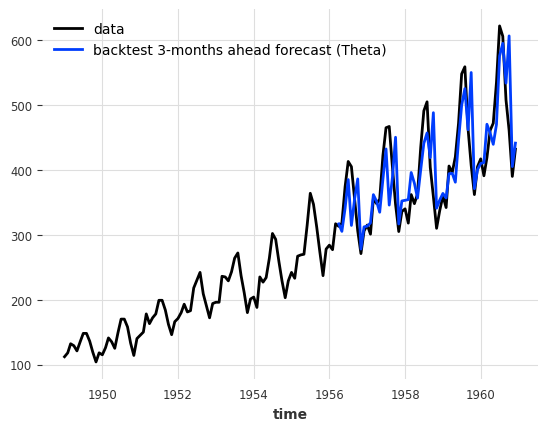

In [ ]:
#@title Backtesting: simulate historical forecasting
#@markdown Once we have a model that looks good based on our current data, we might wonder how it would have performed in the past. This is where backtesting comes in. Backtesting is like a time travel experiment for our model—it lets us simulate how the model would have predicted future events using historical data. This process takes time because we pretend to make predictions at many past points, retraining the model each time as if we were moving through history. We define a 'forecast horizon' to specify how far into the future we want to predict—like looking three months ahead from any point in time.

#@markdown Backtesting not only tests the effectiveness of the model over historical data but also helps in identifying overfitting. Overfitting occurs when a model learns the details and noise in the training data to an extent that it negatively impacts the performance of the model on new data. This is especially critical in forecasting, where overfitting can lead to overly optimistic results during the backtesting phase. If the MAPE is significantly better on historical data compared to new, unseen data, it may indicate that the model has overfit the historical data.

#@markdown The MAPE score can provide insights into the model's predictive power over time. A high MAPE value in the backtesting phase compared to the training phase can alert us to potential overfitting.

#@markdown Press ▶
historical_fcast_theta = best_theta_model.historical_forecasts(
    series, start=0.6, forecast_horizon=3, verbose=True
)

series.plot(label="data")
historical_fcast_theta.plot(label="backtest 3-months ahead forecast (Theta)")
print("MAPE = {:.2f}%".format(mape(historical_fcast_theta, series)))



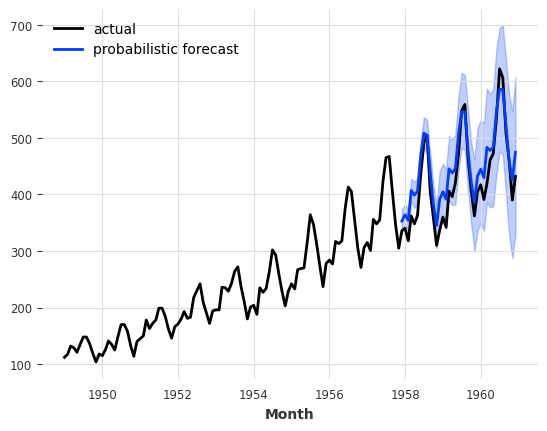

In [ ]:
#@title Probabilistic forecasts
#@markdown Some models can give us forecasts that include a range of possible outcomes, not just a single number. This is helpful because it shows us not just what might happen, but how certain or uncertain the model is about its prediction

#@markdown Press ▶
model_es = ExponentialSmoothing()
model_es.fit(train)
probabilistic_forecast = model_es.predict(len(val), num_samples=500)

series.plot(label="actual")
probabilistic_forecast.plot(label="probabilistic forecast")
plt.legend()
plt.show()

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | res_blocks      | ModuleList       | 166    | train
-------------------------------------------------------------
166       Trainable params
0         Non-trainable params
166       Total params
0.001     Total estimated m

Training: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=400` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

<Axes: xlabel='Month'>

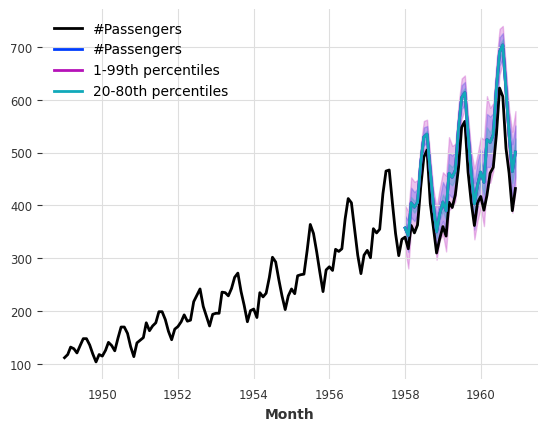

In [ ]:
#@title With neural networks
#@markdown Earlier on we used traditional algorithms, now let's train with a neural network.

#@markdown Press ▶
from darts.models import TCNModel
from darts.utils.likelihood_models import LaplaceLikelihood
from darts.dataprocessing.transformers import Scaler
from darts.datasets import AirPassengersDataset

series_air = AirPassengersDataset().load().astype(np.float32)

# set aside last 36 months of each series as validation set:
train_air, val_air = series_air[:-36], series_air[-36:]

scaler = Scaler()
train_air_scaled = scaler.fit_transform([train_air])

# set aside last 36 months of each series as validation set:
train_air, val_air = series_air[:-36], series_air[-36:]

model = TCNModel(
    input_chunk_length=24,
    output_chunk_length=12,
    random_state=42,
    likelihood=LaplaceLikelihood(),
)

model.fit(train_air_scaled, epochs=400, verbose=True)

pred = model.predict(n=36, num_samples=500)

# scale back:
pred = scaler.inverse_transform(pred)

series_air.plot()
pred.plot()
pred.plot(low_quantile=0.01, high_quantile=0.99, label="1-99th percentiles")
pred.plot(low_quantile=0.2, high_quantile=0.8, label="20-80th percentiles")

In [ ]:
#@title Evaluating Probabilistic Forecasts
#@markdown When we analyze forecasts for the Monthly Air Passengers Dataset, which records passenger numbers from 1949 to 1960, we typically look at the middle value (the median) of our predictions to gauge how accurate they are. This is akin to finding the middle of a list of numbers to see what value appears most central.

#@markdown In addition to evaluating the median, it's helpful to consider different levels of certainty in our predictions. For example, using a "rho" value of 0.05 can tell us about the lower number of passengers we might expect in the least busy months 5% of the time, while a "rho" of 0.95 gives insights into the peak travel months, or the highest number of passengers we might expect 5% of the time. This helps us understand the range of possible outcomes, from slower months to peak travel times, which is crucial for planning and managing resources in the airline industry.

#@markdown Press ▶
from darts.metrics import qr

print("MAPE of median forecast: %.2f" % mape(series_air, pred))
for rho in [0.05, 0.1, 0.5, 0.9, 0.95]:
    rr = qr(series_air, pred)
    print("rho-risk at quantile %.2f: %.2f" % (rho, rr))

MAPE of median forecast: 13.03
rho-risk at quantile 0.05: 0.13
rho-risk at quantile 0.10: 0.13
rho-risk at quantile 0.50: 0.13
rho-risk at quantile 0.90: 0.13
rho-risk at quantile 0.95: 0.13


The consistent quantile loss across different levels (0.13) of the forecast suggests that the model's predictive accuracy doesn't vary much across different scenarios—from the most pessimistic (5th percentile) to the most optimistic forecasts (95th percentile). This can be beneficial because it implies stable performance regardless of the scenario considered. However, it also might suggest a need to review the model or data, as real-world data often show more variability across different scenarios, which might not be fully captured by the model.

historical forecasts: 100%|██████████| 57/57 [00:00<00:00, 99.05it/s]

MAPE = 11.88


<Axes: xlabel='time'>

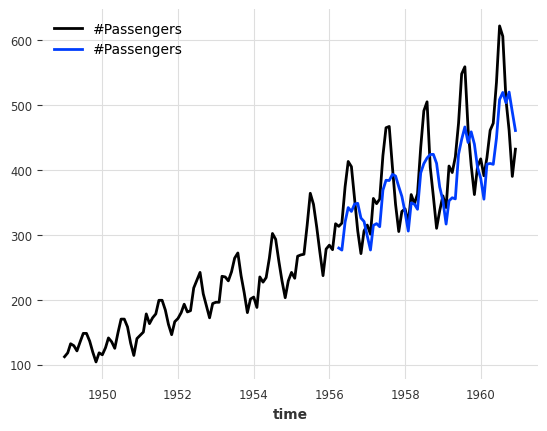

In [ ]:
#@title Ensembling models: Naive Ensembling
#@markdown Ensembling involves combining predictions from several different models to get a final prediction. The idea is that by pooling together different models, we might get a more accurate result. For example, we might take two simple models—one that looks at seasonal patterns and another that looks at trends—and average their predictions to improve accuracy.

#@markdown Press ▶
from darts.models import NaiveEnsembleModel

models = [NaiveDrift(), NaiveSeasonal(12)]

ensemble_model = NaiveEnsembleModel(forecasting_models=models)

backtest = ensemble_model.historical_forecasts(
    series_air, start=0.6, forecast_horizon=3, verbose=True
)

print("MAPE = %.2f" % (mape(backtest, series_air)))
series_air.plot()
backtest.plot()

historical forecasts: 100%|██████████| 57/57 [00:01<00:00, 44.24it/s]

MAPE = 4.85


<Axes: xlabel='time'>

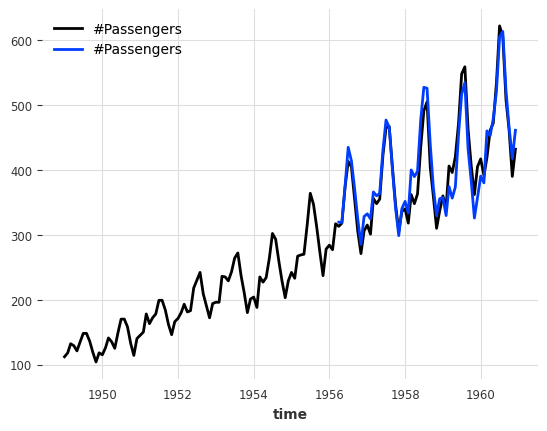

In [ ]:
#@title Ensembling models: Learned Ensembling
#@markdown Simply averaging the predictions of different models (a method we call 'naive ensembling') might not always give the best results. However, it's a starting point. We can also approach combining models as a more sophisticated problem, where we look for the best way to blend different predictions to reduce errors. This method treats the combination of forecasts like a puzzle, trying to find the best fit to get closer to the actual outcomes

#@markdown Press ▶

from darts.models import RegressionEnsembleModel

models = [NaiveDrift(), NaiveSeasonal(12)]

ensemble_model = RegressionEnsembleModel(
    forecasting_models=models, regression_train_n_points=12
)

backtest = ensemble_model.historical_forecasts(
    series_air, start=0.6, forecast_horizon=3, verbose=True
)

print("MAPE = %.2f" % (mape(backtest, series_air)))
series_air.plot()
backtest.plot()

historical forecasts: 100%|██████████| 57/57 [00:02<00:00, 27.69it/s]

MAPE = 4.81


<Axes: xlabel='time'>

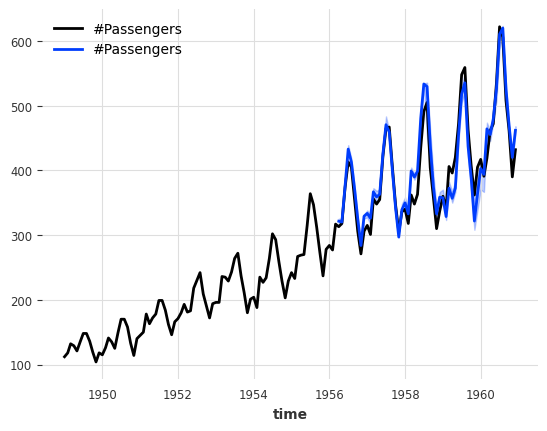

In [ ]:
#@markdown By using a probabilistic regression model, the RegressionEnsembleModel can also generate probabilistic forecasts:

ensemble_model.fit(series_air)

from darts.models import LinearRegressionModel

quantiles = [0.25, 0.5, 0.75]

models = [NaiveDrift(), NaiveSeasonal(12)]

regression_model = LinearRegressionModel(
    quantiles=quantiles,
    lags_future_covariates=[0],
    likelihood="quantile",
    fit_intercept=False,
)

ensemble_model = RegressionEnsembleModel(
    forecasting_models=models,
    regression_train_n_points=12,
    regression_model=regression_model,
)

backtest = ensemble_model.historical_forecasts(
    series_air, start=0.6, forecast_horizon=3, num_samples=500, verbose=True
)

print("MAPE = %.2f" % (mape(backtest, series_air)))
series_air.plot()
backtest.plot()

#@markdown Press ▶

As people who work with data, it's crucial for us to remember that models are tools with limitations. We should always be cautious and critical of the results, especially when dealing with small datasets. Think of it as being a bit skeptical and always double-checking before relying on a model's predictions. It's all about applying a careful, questioning approach—much like in science—to ensure we make the best forecasts possible. Happy modeling, and remember to keep questioning and exploring!

Happy modeling!😀

# BYOD (Bring your own data) 🔢

**Data Upload and Security Assurance**

When you upload data to this Google Colab notebook, please be assured of its safety. Here are the measures we take to protect your information:

- **Temporary Storage:** All files uploaded during your session are stored temporarily. They are held only for the duration of the session and are not transferred to any permanent storage facilities.
- **Automatic Deletion:** Once your session is terminated, either by your action or by the system following a period of inactivity, all uploaded files are automatically deleted from the system.
- **Session Isolation:** Your session is completely isolated. This means that the data you upload can only be accessed by you during your session and is not visible to other users.
- **Data Integrity:** We prioritize maintaining the integrity of your data. There are stringent measures in place to prevent unauthorized access and ensure that your data remains intact and unaltered during your session.

These protocols are designed to ensure that your data is handled securely and with the utmost respect for your privacy.


In [ ]:
#@title Upload an your own .csv file with the following format and column titles:
#@markdown X = "Date" and  Y = "Variable"

#@markdown Press ▶
from google.colab import files
uploaded = files.upload() # This will prompt user to upload a csv
for csv_path in uploaded.keys():
    # check if the user uploaded a file with a csv extension
    if not csv_path.endswith(".csv"):
        print(f"File {csv_path} is not a .csv file. Please upload a .csv file.")
        continue
    df = pd.read_csv(csv_path, delimiter=",")
    if df.empty:
        print(f"File {csv_path} is empty. Please remove it from the files and re-upload!")
        continue

In [ ]:
#@title Now type in the name of your file (including the .csv extension) and let's take a look at its format.

#@markdown Press ▶

dataset_name = '' #@param {type:"string"}

if dataset_name == "":
    print("Please enter the name of your dataset.")
else:
    if not dataset_name.endswith(".csv"):
        dataset_name += ".csv"

try:
    df = pd.read_csv(dataset_name, delimiter=",")
    display(df.head())
except Exception as e:
    print(f"An error occurred: {e}")


# # Widget for inputting the dataset file name
# dataset_input = widgets.Text(
#     value='',
#     placeholder='Enter dataset file name here',
#     description='Dataset:',
#     disabled=False
# )

# # Button to load and display the specified dataset
# load_dataset_button = widgets.Button(description="Load Dataset")

# # Output widget for displaying the dataframe
# output = widgets.Output()

# display(dataset_input, load_dataset_button, output)

# def on_load_dataset_button_clicked(b):
#     with output:
#         output.clear_output()

#         dataset_name = dataset_input.value
#         try:
#             df = pd.read_csv(dataset_name, delimiter=",")
#             display(df.head())
#         except Exception as e:
#             print(f"An error occurred: {e}")

# # Link the button click event to the function
# load_dataset_button.on_click(on_load_dataset_button_clicked)

In [ ]:
#@title Let's take a look at the data and split it up for training and validation.

#@markdown Press ▶

date_column_title = '' #@param {type:"string"}
variable_column_title = '' #@param {type:"string"}


# Create a TimeSeries object from the DataFrame
series = TimeSeries.from_dataframe(df, time_col=date_column_title, value_cols=[variable_column_title], fill_missing_dates=True)

# Split the data into training and validation sets
train, val = series.split_before(0.75)

# Plot the training and validation data
plt.figure(figsize=(10, 6))
train.plot(label="training")
val.plot(label="validation")
plt.legend()
plt.show()

In [ ]:
#@title Now lets run an **Exponential Smoothing** algorithm and see how it does on past historical data! Press  ▶ to train the model.

#@markdown Press ▶

model_es = ExponentialSmoothing()
model_es.fit(train)
#probabilistic_forecast = model_es.predict(len(val), num_samples=500)
forecast = model_es.predict(len(val))


series.plot(label="actual")
#probabilistic_forecast.plot(label="probabilistic forecast")
forecast.plot(label="forecast")

plt.legend()
plt.show()
print("model {} obtains MAPE: {:.2f}%".format(model_es, mape(val, forecast)))

In [ ]:
#@title Pretty good! Now lets forecast into the future. Provide the number of days below to forcast.

# Assuming 'series' is your TimeSeries object and has been defined previously

#@markdown > 💡 For best results keep your forecast less than 30 days in the future!

# Widget for specifying the number of days for forecasting
number_of_future_days = 0 #@param {type:"number"}

# Initialize and fit the Exponential Smoothing model
model_es = ExponentialSmoothing()
model_es.fit(series)

# Generate forecast
forecast = model_es.predict(number_of_future_days)

# Get the forecasted values as a DataFrame
numeric_forecast = forecast.pd_dataframe()

# Plot the original series and the forecast
plt.figure(figsize=(10, 6))
series.plot(label="Actual")
forecast.plot(label="Forecast")
plt.legend()
plt.show()

# Display the forecasted numeric values
print(numeric_forecast)

# Quiz ❓

In [ ]:
#@title Press ▶ to begin!

#@markdown Complete each cell by filling out the multiple choice number and then press ▶ to record your answers.

#@markdown **Make sure you have run the Software Setup cells at the beginning of the notebook to finish this quiz.**

print("Let's begin!")

Let's begin!


In [ ]:
#@title Q1: What does `MAPE` stand for? (Choose 1-4 and type in the number below.)
#@markdown 1. Mean Absolute Possible Extension
#@markdown 2. Mean Average Percent Evaluation
#@markdown 3. Mean Absolute Percentage Error
#@markdown 4. Mean Average Percentage Error

answer = "3" #@param {type:"string"}
user_answers["1"] = answer

#@markdown Press ▶

print("Answer recorded, thank you!")

Answer recorded, thank you!


In [ ]:
#@title Q2: What are the essential components of a basic time series dataframe? (Choose 1-4 and type in the number below.)
#@markdown 1. Email and Password
#@markdown 2. Date and Variable
#@markdown 3. Latitude and Longitude
#@markdown 4. Filename and Size

answer = "2" #@param {type:"string"}
user_answers["2"] = answer

#@markdown Press ▶

print("Answer recorded, thank you!")


Answer recorded, thank you!


In [ ]:
#@title Q3: What is the first step in preparing your data for time series forecasting? (Choose 1-4 and type in the number below.)
#@markdown 1. Deciding on the color scheme for your plots
#@markdown 2. Selecting the forecasting model to use
#@markdown 3. Collecting your observations and ensuring dates are accurate
#@markdown 4. Publishing your results

answer = "3" #@param {type:"string"}
user_answers["3"] = answer

#@markdown Press ▶

print("Answer recorded, thank you!")


Answer recorded, thank you!


In [ ]:
#@title Q4: What does a 'naive' forecasting model typically use for predictions in time series analysis? (Choose 1-4 and type in the number below.)
#@markdown 1. The average value of the series
#@markdown 2. A random value from the series
#@markdown 3. The very last observed value
#@markdown 4. The first observed value

answer = "3" #@param {type:"string"}
user_answers["4"] = answer

#@markdown Press ▶

print("Answer recorded, thank you!")


Answer recorded, thank you!


In [ ]:
#@title Final Score
#@markdown Press ▶ to calculate final score.

# Call the function to check answers and calculate the final score
final_grade, is_perfect = grade(user_answers, key)

if is_perfect:
  print("\n")
  print("You have successfully completed this lab!")
  print("Please copy and paste the following code into the LMS: \n")
  print(lmscode)


Question 1: Correct!
Question 2: Correct!
Question 3: Correct!
Question 4: Correct!
--------------------------------------------------------------------------
Final Score: 100.0% (4 out of 4 correct)
--------------------------------------------------------------------------


You have successfully completed this lab!
Please copy and paste the following code into the LMS: 

deHn6E6ARRK5zeuj
